# E04 — Gestión de un libro de estructurados

**Objetivos:** agregar los riesgos de un libro de autocallables (delta, gamma, vega, skew, dividendos); ver la gamma
cerca de una barrera; entender por qué todos los emisores acumulan los mismos riesgos y cómo eso mueve los precios;
reciclar riesgo con inversores institucionales; vender dividendos a un hedge fund con un swap y medir la reducción;
ver cómo un índice de *decremento* traslada el riesgo de dividendos al inversor.

**Fuentes:** Schofield, *Equity Derivatives*, cap. 12 (12.7), 13 (13.2, 13.5) y 14; los índices de decremento no
están en los materiales y se tratan como contexto de mercado. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

import time
from scipy.stats import norm
from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.equity import EquityMarket, SSVI, local_vol_mc
from derivlab import equity_market as em
from derivlab.structured import perf_from_x, funding_dfs, autocall_cashflows, note_value, bump_dividends
from derivlab.exotics import bs_spot, digital_flat

estr, eur = build_curves(sample_market())
mkt = EquityMarket(estr)
surface = SSVI()
SPREAD = 0.008
q_obs = np.arange(1, 21) * 0.25

# The book: Phoenix notes sold to clients with the E3 design (coupon barrier 60%, capital barrier 50%, memory,
# quarterly autocall at 100% from the end of the first year; B and C are already past it)
book = pd.DataFrame([
    {"note": "A (issued today)", "initial level": 5000.0, "quarters left": 20, "first autocall": 4, "notional": 300e6, "coupon": 0.060},
    {"note": "B (issued 1y ago)", "initial level": 5400.0, "quarters left": 16, "first autocall": 1, "notional": 200e6, "coupon": 0.055},
    {"note": "C (issued 2y ago)", "initial level": 4600.0, "quarters left": 12, "first autocall": 1, "notional": 250e6, "coupon": 0.060},
])
book["moneyness"] = mkt.spot / book["initial level"]
print(book.to_string(index=False, formatters={"notional": "{:,.0f}".format, "coupon": "{:.2%}".format, "moneyness": "{:.1%}".format}))

             note  initial level  quarters left  first autocall    notional coupon moneyness
 A (issued today)         5000.0             20               4 300,000,000  6.00%    100.0%
B (issued 1y ago)         5400.0             16               1 200,000,000  5.50%     92.6%
C (issued 2y ago)         4600.0             12               1 250,000,000  6.00%    108.7%


## 1. Valorar el libro y calcular sus riesgos

El banco ha vendido las notas: su posición es **menos** el valor de cada nota. Se simula una sola vez $x = \ln(S/F)$
con la volatilidad local y se revalúa con mercados movidos:

- **Delta y gamma:** el spot se mueve ±1 % (en la simulación, $x_0 = \ln(1 \pm 0{,}01)$, mismos números aleatorios).
- **Vega:** la volatilidad ATM de toda la superficie sube un punto y se recalcula la volatilidad local.
- **Skew:** la correlación $\rho$ de SSVI pasa de −0,75 a −0,80 (puts más caras, calls más baratas).
- **Dividendos:** un punto más de dividendo en cada año, con las mismas trayectorias de $x$ (el smile se queda
  fijo en moneyness).

In [2]:
N_PATHS, SPY, SEED = 40000, 250, 21

def simulate(surf, x0=0.0):
    _, x = local_vol_mc(surf, 5.0, n_paths=N_PATHS, steps_per_year=SPY, seed=SEED, obs_times=q_obs, t_max=5.0, x0=x0)
    return x

def note_pv(m, x, row):
    n = int(row["quarters left"])
    obs = q_obs[:n]
    perf = perf_from_x(m, obs, x[:, :n], spot_ref=row["initial level"])
    cf, called = autocall_cashflows(perf, row["coupon"] / 4, 0.60, 1.0, 0.50, True, False, int(row["first autocall"]))
    return row["notional"] * note_value(cf, funding_dfs(estr, obs, SPREAD)), called

def bank_value(m, x):
    """Bank's position: minus the value of the notes it sold."""
    return -sum(note_pv(m, x, row)[0] for _, row in book.iterrows())

t0 = time.time()
x_base = simulate(surface)
x_up, x_dn = simulate(surface, np.log(1.01)), simulate(surface, np.log(0.99))
x_vega = simulate(SSVI(atm_vol_fn=lambda T: em.atm_vol(T) + 0.01))
x_skew = simulate(SSVI(rho=-0.80))
print(f"five local-vol simulations in {time.time() - t0:.0f} s")

v0 = bank_value(mkt, x_base)
per_note = pd.DataFrame([{"note": row["note"], "value (% of notional)": note_pv(mkt, x_base, row)[0] / row["notional"]}
                         for _, row in book.iterrows()])
print(per_note.to_string(index=False, formatters={"value (% of notional)": "{:.2%}".format}))
vu, vd = bank_value(mkt, x_up), bank_value(mkt, x_dn)
risk = pd.Series({
    "delta (EUR per 1% index move)": (vu - vd) / 2,
    "delta (index units)": (vu - vd) / (0.02 * mkt.spot),
    "gamma (change in EUR delta per 1% move)": vu - 2 * v0 + vd,
    "vega (EUR per vol point)": bank_value(mkt, x_vega) - v0,
    "skew (EUR for rho -0.75 -> -0.80)": bank_value(mkt, x_skew) - v0,
})
print(risk.map(lambda v: f"{v:,.0f}").to_string())
print(f"CASE book of {book.notional.sum() / 1e6:,.0f} M EUR: bank position {v0 / 1e6:,.1f} M EUR; vega {risk.iloc[3]:,.0f} EUR per vol point")

five local-vol simulations in 44 s


             note value (% of notional)
 A (issued today)                97.83%
B (issued 1y ago)                96.27%
C (issued 2y ago)                99.70%


delta (EUR per 1% index move)              -3,520,104
delta (index units)                           -70,402
gamma (change in EUR delta per 1% move)       475,074
vega (EUR per vol point)                    3,481,079
skew (EUR for rho -0.75 -> -0.80)             962,671
CASE book of 750 M EUR: bank position -735.3 M EUR; vega 3,481,079 EUR per vol point


In [3]:
div_rows = []
for k, year in enumerate(em.DIVIDEND_YEARS[:5]):
    div_rows.append({"year": year, "bank P&L per +1 dividend point (EUR)": bank_value(bump_dividends(mkt, k, 1.0), x_base) - v0})
div_risk = pd.DataFrame(div_rows)
div_risk["futures equivalent (100 EUR/pt)"] = div_risk.iloc[:, 1] / 100
print(div_risk.to_string(index=False, formatters={"bank P&L per +1 dividend point (EUR)": "{:,.0f}".format,
                                                 "futures equivalent (100 EUR/pt)": "{:,.0f}".format}))
print(f"CASE the book is long dividends: {div_risk.iloc[0, 1]:,.0f} EUR per point in 2027, {div_risk.iloc[1, 1]:,.0f} in 2028, "
      f"{div_risk.iloc[2, 1]:,.0f} in 2029")

 year bank P&L per +1 dividend point (EUR) futures equivalent (100 EUR/pt)
 2027                               11,361                             114
 2028                               12,027                             120
 2029                                7,308                              73
 2030                                6,771                              68
 2031                                1,598                              16
CASE the book is long dividends: 11,361 EUR per point in 2027, 12,027 in 2028, 7,308 in 2029


**Lectura del libro.**

- **Vega positiva** a largo plazo: el banco compró a los clientes puts *down-and-in* a cinco años. Si la
  volatilidad sube, gana; si baja, pierde.
- **Skew:** al hacerse más caras las puts de strike bajo, el banco gana; es largo skew.
- **Dividendos:** largo. Si las empresas pagan más, el forward baja y las puts que tiene el banco valen más (y las
  notas se amortizan menos). El riesgo se concentra en los primeros años porque la mayoría de las notas se
  amortizan pronto.
- **Delta y gamma:** el banco cubre la delta con futuros. La gamma del libro depende de dónde está el índice
  respecto de las barreras de cada serie.

Todos los emisores de autocallables tienen el mismo libro. Por eso todos venden volatilidad larga, dividendos y
skew para cubrirse, y esa presión deja la volatilidad larga, los futuros de dividendos y el skew más baratos de lo
que justificarían los fundamentales (Schofield 12.7.3). En una caída fuerte, los mismos libros necesitan cubrir a
la vez lo mismo, y los precios se mueven contra todos.

## 2. Gamma cerca de una barrera de capital

Una nota con tres meses de vida y el índice cerca de la barrera de capital del 50 % concentra el riesgo: al
vencimiento, cruzar la barrera cambia el pago del 100 % a la rentabilidad del índice. En el lado del banco es una
put más una digital put larga, y su gamma cambia de signo en la barrera. Volatilidad plana del 35 % para la
ilustración.

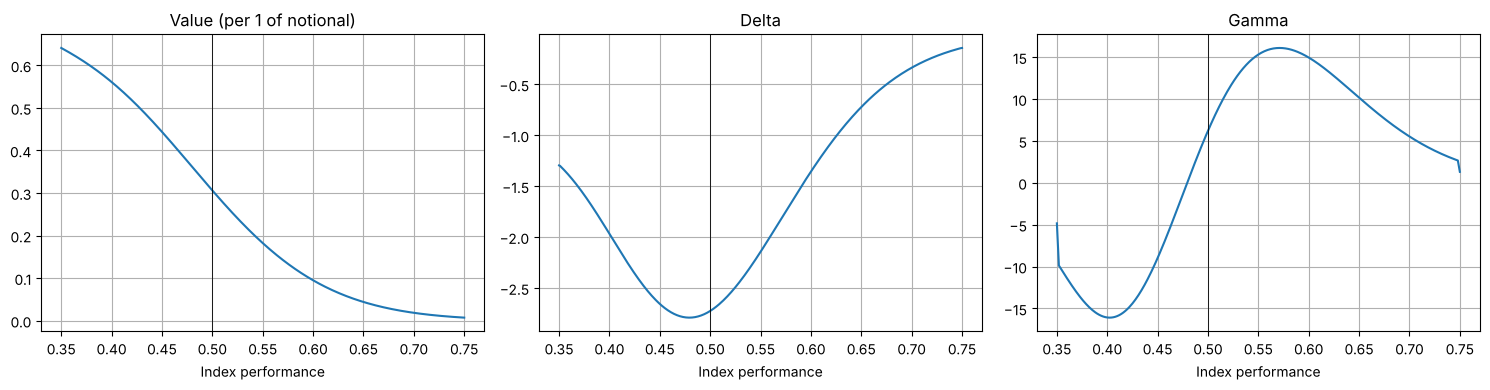

CASE gamma at 53% performance +12.9, at 47% -3.0 (per unit of performance): it flips sign at the barrier


In [4]:
T_left, B, vol_b = 0.25, 0.50, 0.35
r_b = -np.log(discount_t(estr, T_left)) / T_left
q_b = 0.034
def bank_side(perf):
    """Long put at the barrier plus long (1 - B) digital put: what the bank gains when the capital is lost."""
    return bs_spot(perf, B, T_left, r_b, q_b, vol_b, call=False) + (1 - B) * digital_flat(perf, B, T_left, r_b, q_b, vol_b, call=False)
grid = np.linspace(0.35, 0.75, 401)
val = np.array([bank_side(p) for p in grid])
delta = np.gradient(val, grid)
gamma = np.gradient(delta, grid)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, y, t in zip(ax, [val, delta, gamma], ["Value (per 1 of notional)", "Delta", "Gamma"]):
    a.plot(grid, y); a.axvline(B, color="k", lw=0.6); a.set_title(t); a.set_xlabel("Index performance")
plt.tight_layout(); plt.show()
g_above, g_below = gamma[np.searchsorted(grid, 0.53)], gamma[np.searchsorted(grid, 0.47)]
print(f"CASE gamma at 53% performance {g_above:+.1f}, at 47% {g_below:+.1f} (per unit of performance): it flips sign at the barrier")

## 3. Caso: vender dividendos a un hedge fund

**Situación.** El libro está largo dividendos de 2027 a 2029. El responsable del libro quiere reducir esa
exposición antes de que un recorte de dividendos le haga perder. Un hedge fund cree que los dividendos cotizan
baratos (D4) y está dispuesto a comprarlos: el banco entra en un **swap de dividendos** en el que paga los
dividendos que realmente pague el índice y recibe un fijo igual al precio de los futuros (168, 165 y 160
puntos). Cubre el 75 % de la sensibilidad de cada año.

In [5]:
hedge_ratio = 0.75
swap = div_risk.iloc[:3, :2].copy()
swap.columns = ["year", "book EUR per point"]
swap["swap notional (EUR per point)"] = -np.round(hedge_ratio * swap["book EUR per point"] / 1000) * 1000
swap["fixed (points)"] = em.DIVIDENDS_MARKET[:3]
swap["residual EUR per point"] = swap["book EUR per point"] + swap["swap notional (EUR per point)"]
print(swap.to_string(index=False, formatters={c: "{:,.0f}".format for c in swap.columns if c not in ("year", "fixed (points)")}))

cut = 0.35
divs_cut = [(t, d * (1 - cut) if k < 3 else d) for k, (t, d) in enumerate(mkt.divs)]   # 2027, 2028 and 2029
mkt_cut = mkt.with_dividends(divs_cut)
book_loss = bank_value(mkt_cut, x_base) - v0
cut_points = cut * np.array(em.DIVIDENDS_MARKET[:3])
swap_gain = (-swap["swap notional (EUR per point)"] * cut_points).sum()      # bank pays realised, receives fixed
res = pd.Series({"book (full revaluation)": book_loss, "dividend swap": swap_gain, "hedged total": book_loss + swap_gain,
                 "linear estimate, unhedged": -(swap["book EUR per point"] * cut_points).sum()})
print(f"Scenario: 2027-2029 dividends 35% below the futures")
print(res.map(lambda v: f"{v:,.0f} EUR").to_string())
print(f"CASE a 35% dividend cut costs the book {-book_loss / 1e6:.2f} M EUR; with the swap the loss falls to "
      f"{-(book_loss + swap_gain) / 1e6:.2f} M EUR ({1 + (book_loss + swap_gain) / -book_loss:.0%} less)")

 year book EUR per point swap notional (EUR per point)  fixed (points) residual EUR per point
 2027             11,361                        -9,000           168.0                  2,361
 2028             12,027                        -9,000           165.0                  3,027
 2029              7,308                        -5,000           160.0                  2,308
Scenario: 2027-2029 dividends 35% below the futures
book (full revaluation)      -2,275,096 EUR
dividend swap                 1,328,950 EUR
hedged total                   -946,146 EUR
linear estimate, unhedged    -1,771,809 EUR
CASE a 35% dividend cut costs the book 2.28 M EUR; with the swap the loss falls to 0.95 M EUR (58% less)


**Lectura.**

- El swap reduce la pérdida del escenario a menos de la mitad, pero no en el 75 % que sugiere el ratio de
  cobertura: con un recorte grande la revaluación completa pierde bastante más de lo que estima la sensibilidad a
  un punto, porque al cambiar tanto el forward cambian también las probabilidades de amortización y de cupón. Un
  swap dimensionado con la delta no cubre esa convexidad; para recortes grandes hay que medirla y cubrir algo más
  o comprar opciones sobre dividendos.
- El banco paga una prima implícita: vende los dividendos al precio de los futuros, que ya cotizan por debajo de las
  previsiones. Es el precio de reciclar el riesgo.
- El hedge fund asume riesgo de recorte a cambio de esa prima y de diversificación; el banco reduce consumo de
  capital y límites. El mismo razonamiento sirve para la vega: el libro puede vender volatilidad a cinco años a un
  fondo de pensiones con swaps de varianza (D4).

## 4. Índices de decremento

Un índice de *decremento* se construye a partir del índice de rentabilidad total (con dividendos reinvertidos) y
resta un dividendo sintético fijo, en puntos o en porcentaje. Un producto sobre ese índice no tiene riesgo de
dividendos para el emisor: el forward ya no depende de lo que paguen las empresas. Si el decremento se fija por
encima de los dividendos esperados (por ejemplo, un 5 % anual), el forward es más bajo y el producto puede pagar
más cupón, a cambio de que el índice recoja peor las subidas. Se comparan el libro y el cupón justo de la nota A
sobre un índice de precio y sobre un índice de decremento del 5 %.

In [6]:
mkt_dec5 = EquityMarket(estr, spot=mkt.spot, repo=0.05, divs=[])      # 5% synthetic dividend as a continuous yield
row_a = book.iloc[0]
def fair_coupon(m):
    from derivlab.structured import solve_coupon
    obs = q_obs
    perf = perf_from_x(m, obs, x_base)
    dfs = funding_dfs(estr, obs, SPREAD)
    return solve_coupon(lambda c: note_value(autocall_cashflows(perf, c / 4, 0.60, 1.0, 0.50, True, False, 4)[0], dfs), 0.98, 0.0, 0.5)
dec = pd.DataFrame({
    "price index (futures dividends)": {"5y forward": mkt.forward(5.0), "fair coupon of note A": fair_coupon(mkt)},
    "5% decrement index": {"5y forward": mkt_dec5.forward(5.0), "fair coupon of note A": fair_coupon(mkt_dec5)},
})
print(dec.T.to_string(formatters={"5y forward": "{:,.0f}".format, "fair coupon of note A": "{:.2%}".format}))
print("A dividend cut moves the price-index forward up and leaves the decrement index forward unchanged:")
print(f"  price index 5y forward after a 35% cut in 2027-2029: {mkt_cut.forward(5.0):,.0f} (vs {mkt.forward(5.0):,.0f})")
print(f"CASE note A pays {dec.iloc[1, 0]:.2%} on the price index and {dec.iloc[1, 1]:.2%} on a 5% decrement index, with no dividend risk left to the bank")

                                5y forward fair coupon of note A
price index (futures dividends)      4,667                 6.11%
5% decrement index                   4,356                 6.56%
A dividend cut moves the price-index forward up and leaves the decrement index forward unchanged:
  price index 5y forward after a 35% cut in 2027-2029: 4,852 (vs 4,667)
CASE note A pays 6.11% on the price index and 6.56% on a 5% decrement index, with no dividend risk left to the bank


## 5. Comprobaciones

In [7]:
assert v0 < 0
assert risk["vega (EUR per vol point)"] > 0 and risk["skew (EUR for rho -0.75 -> -0.80)"] > 0
assert (div_risk.iloc[:3, 1] > 0).all()
assert g_above * g_below < 0
assert book_loss < 0 and swap_gain > 0 and abs(book_loss + swap_gain) < 0.5 * abs(book_loss)
assert dec.iloc[1, 1] > dec.iloc[1, 0]
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuántos futuros sobre el índice (10 €/punto) necesita el banco para cubrir la delta del libro?
2. **Intermedio.** ¿Cuántos futuros de dividendos de 2027 (100 €/punto) equivalen a la sensibilidad del libro a los
   dividendos de 2027, y cuántos quedan después del swap?
3. **Avanzado.** El banco quiere reciclar la mitad de su vega vendiendo swaps de varianza a cinco años a un fondo de
   pensiones. Con un strike de varianza del 24,23 % (D4), ¿qué nocional vega y qué nocional de varianza debe vender?

## Soluciones

In [8]:
units = risk["delta (index units)"]
print(f"book delta {units:,.0f} index units -> {'sell' if units > 0 else 'buy'} {abs(units) / 10:,.0f} index futures of 10 EUR per point")

book delta -70,402 index units -> buy 7,040 index futures of 10 EUR per point


In [9]:
f27 = div_risk.iloc[0, 1] / 100
print(f"2027 sensitivity = {f27:,.0f} dividend futures; after the swap {swap['residual EUR per point'].iloc[0] / 100:,.0f}")

2027 sensitivity = 114 dividend futures; after the swap 24


In [10]:
vega_to_sell = 0.5 * risk["vega (EUR per vol point)"]
n_var = vega_to_sell / (2 * 24.23)
print(f"sell {vega_to_sell:,.0f} EUR of vega notional = {n_var:,.0f} EUR per variance point at a strike of 24.23%")
print("Vega notional is per vol point near the strike; the variance swap pays N_var x (sigma^2 - K^2) in vol points squared.")

sell 1,740,540 EUR of vega notional = 35,917 EUR per variance point at a strike of 24.23%
Vega notional is per vol point near the strike; the variance swap pays N_var x (sigma^2 - K^2) in vol points squared.
